In [9]:
import torch, torch.nn as nn, cv2, numpy as np, csv, sys, random, os
from torch.utils.data import Dataset
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

C:\Users\ivany\Documents\PyCharm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
print("Python:", sys.executable)
print("Torch:", torch.__version__)
print("Torch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("Capability:", torch.cuda.get_device_capability(0))

Python: C:\Users\ivany\Documents\PyCharm\.venv\Scripts\python.exe
Torch: 2.14.1+cu132
Torch CUDA: 13.2
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Ti
Capability: (12, 0)


In [3]:
def preprocess(bgr):
    """Remove the sky, shrink the image, and convert to RGB."""
    cropped = bgr[250:, :]                       # keep the road, drop the sky
    small = cv2.resize(cropped, (200, 66))
    return cv2.cvtColor(small, cv2.COLOR_BGR2RGB)

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Running on', device)

Running on cuda


In [12]:
class DrivingDataset(Dataset):
    def __init__(self, folder='data_1'):
        self.root = os.path.join(r'D:\CARLA data', folder)
        with open(os.path.join(self.root, 'log.csv'), newline='') as f:
            rows = list(csv.DictReader(f))

        # OpenCV runs once here. Training reuses these in-memory tensors.
        loaded_images = []
        loaded_steers = []
        for row in rows:
            path = os.path.join(self.root, 'images', row['image'])
            bgr = cv2.imread(path)
            if bgr is None:
                raise FileNotFoundError(f'Could not read image: {path}')
            img = preprocess(bgr).astype(np.float32) / 255.0
            loaded_images.append(torch.from_numpy(img).permute(2, 0, 1))
            loaded_steers.append(float(row['steer']))

        self.images = torch.stack(loaded_images)
        self.steers = torch.tensor(loaded_steers, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return self.images.shape[0]

    def __getitem__(self, i):
        return self.images[i], self.steers[i]

DATA_FOLDER = 'data_1'
full_dataset = DrivingDataset(DATA_FOLDER)
print(f'Loaded {len(full_dataset)} images once with OpenCV.')

Loaded 16342 images once with OpenCV.


In [13]:
# Keep the last part of the recording for validation; random frame splitting leaks near-duplicates.
split_at = int(len(full_dataset) * 0.8)
train_indices = torch.arange(0, split_at, device=device)
val_indices = torch.arange(split_at, len(full_dataset), device=device)

# Move the complete preloaded dataset to GPU once. No OpenCV or CPU loading occurs in training.
images = full_dataset.images.to(device)
steers = full_dataset.steers.to(device)
del full_dataset
train_steers = steers[train_indices, 0]

# Reduce the bias toward straight driving by sampling steering bins more evenly.
bin_edges = torch.linspace(-1.0, 1.0, 21, device=device)
bins = torch.bucketize(train_steers, bin_edges).clamp(1, 20) - 1
counts = torch.bincount(bins, minlength=20).float()
sample_weights = 1.0 / counts[bins].clamp_min(1.0)
sample_weights = sample_weights / sample_weights.sum()

print(f'Train samples: {len(train_indices)}; validation samples: {len(val_indices)}')
print(f'GPU image tensor: {images.shape}, {images.element_size() * images.nelement() / 1024**3:.2f} GB')

Train samples: 13073; validation samples: 3269
GPU image tensor: torch.Size([16342, 3, 66, 200]), 2.41 GB


In [14]:
class SteeringNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 24, 5, stride=2), nn.ReLU(),
            nn.Conv2d(24, 36, 5, stride=2), nn.ReLU(),
            nn.Conv2d(36, 48, 5, stride=2), nn.ReLU(),
            nn.Conv2d(48, 64, 3), nn.ReLU(),
            nn.Conv2d(64, 64, 3), nn.ReLU(),
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.LazyLinear(100), nn.ReLU(), nn.Dropout(0.25),
            nn.Linear(100, 50), nn.ReLU(), nn.Dropout(0.15),
            nn.Linear(50, 1), nn.Tanh()
        )

    def forward(self, x):
        return self.fc(self.conv(x))

In [15]:
model = SteeringNet().to(device)
model(torch.zeros(1, 3, 66, 200, device=device))  # initialize LazyLinear
optim = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
loss_fn = nn.SmoothL1Loss()
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optim, mode='min', factor=0.5, patience=2
)

In [16]:
EPOCHS = 30
BATCH_SIZE = 256
PATIENCE = 5
best_val_loss = float('inf')
epochs_without_improvement = 0
losses = []
val_losses = []

for epoch in range(EPOCHS):
    model.train()
    train_total = 0.0
    train_count = 0

    order = torch.multinomial(sample_weights, len(train_indices), replacement=True)
    selected = train_indices[order]
    for start in range(0, len(selected), BATCH_SIZE):
        indices = selected[start:start + BATCH_SIZE]
        imgs = images[indices]
        labels = steers[indices]

        mirror = torch.rand(imgs.shape[0], device=device) < 0.5
        if mirror.any():
            imgs = imgs.clone()
            imgs[mirror] = torch.flip(imgs[mirror], dims=[3])
            labels = labels.clone()
            labels[mirror] = -labels[mirror]
        brightness = torch.empty(imgs.shape[0], 1, 1, 1, device=device).uniform_(0.8, 1.2)
        imgs = (imgs * brightness).clamp(0.0, 1.0)

        optim.zero_grad(set_to_none=True)
        predictions = model(imgs)
        loss = loss_fn(predictions, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optim.step()

        train_total += loss.item() * imgs.shape[0]
        train_count += imgs.shape[0]

    train_loss = train_total / train_count

    model.eval()
    val_total = 0.0
    val_count = 0
    with torch.no_grad():
        for start in range(0, len(val_indices), BATCH_SIZE):
            indices = val_indices[start:start + BATCH_SIZE]
            batch_val_loss = loss_fn(model(images[indices]), steers[indices])
            val_total += batch_val_loss.item() * len(indices)
            val_count += len(indices)

    val_loss = val_total / val_count
    losses.append(train_loss)
    val_losses.append(val_loss)
    scheduler.step(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(model.state_dict(), '../models/steer_mercedes.pt')
        checkpoint_status = 'saved best'
    else:
        epochs_without_improvement += 1
        checkpoint_status = f'no improvement ({epochs_without_improvement}/{PATIENCE})'

    current_lr = optim.param_groups[0]['lr']
    print(f'Epoch {epoch + 1:02d}: train={train_loss:.4f}, valid={val_loss:.4f}, lr={current_lr:.2e} - {checkpoint_status}')

    if epochs_without_improvement >= PATIENCE:
        print('Early stopping.')
        break

model.load_state_dict(torch.load('../models/steer_mercedes.pt', map_location=device))
torch.save(model.state_dict(), '../models/steer.pt')
print(f'Best validation loss: {best_val_loss:.4f}')

Epoch 01: train=0.0035, valid=0.0004, lr=3.00e-04 - saved best
Epoch 02: train=0.0027, valid=0.0003, lr=3.00e-04 - saved best
Epoch 03: train=0.0026, valid=0.0003, lr=3.00e-04 - saved best
Epoch 04: train=0.0026, valid=0.0003, lr=3.00e-04 - saved best
Epoch 05: train=0.0013, valid=0.0003, lr=3.00e-04 - no improvement (1/5)
Epoch 06: train=0.0007, valid=0.0002, lr=3.00e-04 - saved best
Epoch 07: train=0.0005, valid=0.0002, lr=3.00e-04 - no improvement (1/5)
Epoch 08: train=0.0004, valid=0.0001, lr=3.00e-04 - saved best
Epoch 09: train=0.0003, valid=0.0001, lr=3.00e-04 - saved best
Epoch 10: train=0.0003, valid=0.0001, lr=3.00e-04 - saved best
Epoch 11: train=0.0003, valid=0.0001, lr=3.00e-04 - no improvement (1/5)
Epoch 12: train=0.0002, valid=0.0001, lr=3.00e-04 - saved best
Epoch 13: train=0.0002, valid=0.0001, lr=3.00e-04 - saved best
Epoch 14: train=0.0002, valid=0.0001, lr=3.00e-04 - no improvement (1/5)
Epoch 15: train=0.0002, valid=0.0001, lr=3.00e-04 - saved best
Epoch 16: train

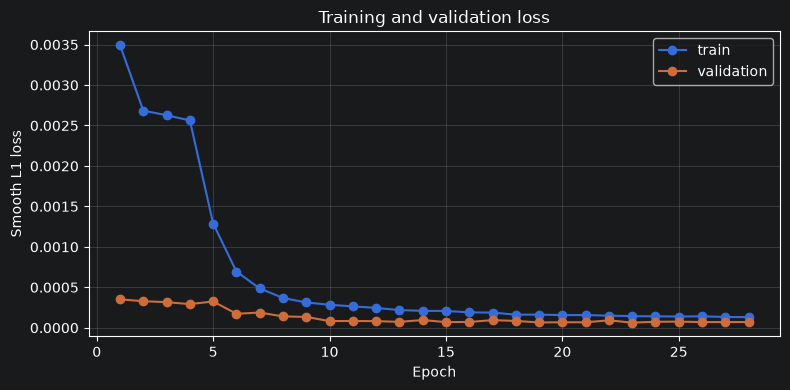

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(losses) + 1), losses, marker='o', label='train')
ax.plot(range(1, len(val_losses) + 1), val_losses, marker='o', label='validation')
ax.set_xlabel('Epoch')
ax.set_ylabel('Smooth L1 loss')
ax.set_title('Training and validation loss')
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

In [13]:
torch.save(model.state_dict(), '../models/steer.pt')
print('Saved steer.pt')

Saved steer.pt


In [18]:
print("Minimum:", steers.min().item())
print("Maximum:", steers.max().item())
print("Mean:", steers.mean().item())
print("Positive:", (steers > 0.05).sum().item())
print("Negative:", (steers < -0.05).sum().item())
print("Straight:", (steers.abs() <= 0.05).sum().item())

Minimum: -0.09320983290672302
Maximum: 0.18262219429016113
Mean: 0.0003217584453523159
Positive: 558
Negative: 561
Straight: 15223
